In [1]:
!pip install kaggle

In [2]:
!kaggle datasets download -d sukmaadhiwijaya/welding-defect-object-detection

Dataset URL: https://www.kaggle.com/datasets/sukmaadhiwijaya/welding-defect-object-detection
License(s): CC0-1.0
100% 152M/152M [00:09<00:00, 16.7MB/s]



In [3]:
!unzip welding-defect-object-detection.zip

Streaming output truncated to the last 5000 lines.
  inflating: The Welding Defect Dataset - v2/The Welding Defect Dataset - v2/train/images/download_jpeg.rf.387779d57c5487141facb913b1ece169.jpg  
  inflating: The Welding Defect Dataset - v2/The Welding Defect Dataset - v2/train/images/download_jpeg.rf.92c59db2866ceebba90c991ed7b0aeda.jpg  
  inflating: The Welding Defect Dataset - v2/The Welding Defect Dataset - v2/train/images/download_jpeg.rf.a7bb1bce7d95e1c44725f718f60d6aa2.jpg  
  inflating: The Welding Defect Dataset - v2/The Welding Defect Dataset - v2/train/images/download_jpeg_jpg.rf.729401ef3d9244ecbfc107bbc00d7f5c.jpg  
  inflating: The Welding Defect Dataset - v2/The Welding Defect Dataset - v2/train/images/e28c2a83-8c90e0b4-c4_jpg.rf.40664e5f4513a283f1fa04553ce91567.jpg  
  inflating: The Welding Defect Dataset - v2/The Welding Defect Dataset - v2/train/images/e28c2a83-8c90e0b4-c4_jpg.rf.665709ed226aed233e36ca3cebac6f35.jpg  
  inflating: The Welding Defect Dataset - v2/Th

In [4]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.4 MB/s eta 0:00:00


In [5]:
from ultralytics import YOLO

print("YOLO Installed Successfully")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO Installed Successfully


In [14]:
%%writefile dataset.yaml

path: /content/The Welding Defect Dataset/The Welding Defect Dataset
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['Bad Weld', 'Good Weld', 'Defect']

Writing dataset.yaml


In [15]:
import os

dataset_path = "/content/The Welding Defect Dataset/The Welding Defect Dataset/train/labels"

classes = os.listdir(dataset_path)

print("Classes:")
for cls in classes:
    print(cls)

Classes:
SampleV2_1_mp4-79_jpg.rf.f39312ebbd59f7d0b3bac978023732b3.txt
good_weld_vid94_jpeg_jpg.rf.58f1d8e90fe0ea253200578b344f7af2.txt
SampleV3_1_mp4-51_jpg.rf.5b91e34244e5a0cb4978f8e919315847.txt
SampleV3_1_mp4-1_jpg.rf.7c113cf86807871998cc55e1522a02fe.txt
SampleV2_2_mp4-25_jpg.rf.816c5e10889161753da074705fd4fef2.txt
good_weld_vid332_jpeg_jpg.rf.31a9c2d5d4d3cc6f248f922a26e824b4.txt
SampleV1_1_mp4-12_jpg.rf.4484b41531c7a03607e372588a360a67.txt
SampleV2_2_mp4-46_jpg.rf.0baa7bc230bed83c0766b44bd1862fc9.txt
SampleV2_1_mp4-32_jpg.rf.886f8ca78b54e48a393d6a773c0e0e5f.txt
SampleV3_1_mp4-37_jpg.rf.664ef0b7b11e099bf7d8af7e9e41435d.txt
bad_weld_vid320_jpeg_jpg.rf.064cba66d5b87a3f1a7bd3cc09b4a313.txt
SampleV2_1_mp4-61_jpg.rf.1055a7e26f04179d5a1d3e3e259cc322.txt
SampleV2_2_mp4-38_jpg.rf.1f256acba76f4912e47fe1826ee26005.txt
Spatters-welding-images_11_jpeg_jpg.rf.0209c1719448ed7beb61d61d1c4bd1a9.txt
SampleV3_2_mp4-20_jpg.rf.714ff430e80176a9be545da034fce892.txt
SampleV3_1_mp4-38_jpg.rf.73a0c38a8adb9

In [16]:
import os

label_file = "/content/The Welding Defect Dataset/The Welding Defect Dataset/train/labels/0e538f39-1d30436c-c23_jpg.rf.05ff78024b481ae4fada24ef439ebd97.txt"

with open(label_file,"r") as f:
    print(f.read())

2 0.525 0.41484375 0.178125 0.41796875



In [18]:
from collections import Counter

counter = Counter()

label_dir = os.path.join("/content/The Welding Defect Dataset/The Welding Defect Dataset/train", "labels")

for file in os.listdir(label_dir):

    if file.endswith(".txt"):

        with open(os.path.join(label_dir, file)) as f:

            for line in f:
                class_id = int(line.split()[0])
                counter[class_id] += 1

print(counter)

Counter({2: 1298, 1: 1111, 0: 736})


In [19]:
import glob

bad_files = []

for file in glob.glob("/content/The Welding Defect Dataset/The Welding Defect Dataset/train/labels/*.txt"):
    with open(file) as f:
        for line_num, line in enumerate(f, start=1):
            if len(line.split()) != 5:
                bad_files.append((file, line_num, line.strip()))

print("Bad annotations:", len(bad_files))

for item in bad_files[:10]:
    print(item)

Bad annotations: 0


(np.float64(-0.5), np.float64(639.5), np.float64(639.5), np.float64(-0.5))

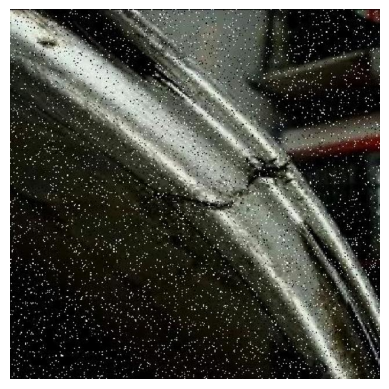

In [20]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread(
"/content/The Welding Defect Dataset/The Welding Defect Dataset/train/images/0e538f39-1d30436c-c23_jpg.rf.77546dd3e656d80bb16894a47fb55b27.jpg"
)

image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.axis("off")

In [22]:
from ultralytics import YOLO

model = YOLO('yolo11n.pt')

model.train(
    data='dataset.yaml',
    epochs=100,
    imgsz=800,
    batch=16,
    patience = 30
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7dd355c99be0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [23]:
from collections import Counter
import glob

counter = Counter()

for file in glob.glob(
    "/content/The Welding Defect Dataset/The Welding Defect Dataset/train/labels/*.txt"
):
    with open(file) as f:
        for line in f:
            counter[int(line.split()[0])] += 1

print(counter)

Counter({2: 1298, 1: 1111, 0: 736})


In [ ]:
from ultralytics import YOLO

model = YOLO(
"/content/runs/detect/train/weights/best.pt"
)

metrics = model.val()

print(metrics)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1762.7±717.2 MB/s, size: 38.9 KB)
val: Scanning /content/The Welding Defect Dataset/The Welding Defect Dataset/valid/labels.cache... 176 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 176/176 67.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 1.8it/s 6.2s
                   all        176        573      0.388      0.364      0.328      0.164
                 Crack         87        127      0.359      0.528      0.345      0.168
              Porosity        119        253      0.516      0.549      0.525      0.278
               Spatter         90        193      0.289     0.0155      0.113     0.0464
Speed: 4.3ms preprocess, 16.8ms inference, 0.0ms loss, 3.1ms postprocess per image
Result

In [24]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")

results = model.predict(
    source="/content/The Welding Defect Dataset/The Welding Defect Dataset/test/images/SampleV1_1_mp4-1_jpg.rf.3f50c974a91c4e6348dd49491f06def8.jpg",
    conf=0.25,
    save=True
)


image 1/1 /content/The Welding Defect Dataset/The Welding Defect Dataset/test/images/SampleV1_1_mp4-1_jpg.rf.3f50c974a91c4e6348dd49491f06def8.jpg: 800x800 4 Bad Welds, 9 Good Welds, 5 Defects, 15.7ms
Speed: 2.6ms preprocess, 15.7ms inference, 1.3ms postprocess per image at shape (1, 3, 800, 800)
Results saved to /content/runs/detect/predict


In [25]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")

model.predict(
    source="/content/The Welding Defect Dataset/The Welding Defect Dataset/test/images",
    save=True
)


image 1/74 /content/The Welding Defect Dataset/The Welding Defect Dataset/test/images/02fd0af7-51ab46bb-c13_jpg.rf.7de08cd3b264d9098d09f5fe6d21c959.jpg: 800x800 (no detections), 15.7ms
image 2/74 /content/The Welding Defect Dataset/The Welding Defect Dataset/test/images/1aa4b44c-d01b8a11-Hot-crack_jpg.rf.57393ca7936f061ca5991481b2b5c485.jpg: 800x800 1 Defect, 15.6ms
image 3/74 /content/The Welding Defect Dataset/The Welding Defect Dataset/test/images/295992d6-f617b725-c1_png_jpg.rf.5f645e13f1695df588b0644ca9702c43.jpg: 800x800 (no detections), 15.7ms
image 4/74 /content/The Welding Defect Dataset/The Welding Defect Dataset/test/images/4a05306b-ca866e1f-c12_jpg.rf.c5c926823394e6056b533bedd6e64c99.jpg: 800x800 1 Bad Weld, 1 Good Weld, 15.7ms
image 5/74 /content/The Welding Defect Dataset/The Welding Defect Dataset/test/images/Good-Welding-images_12_jpeg_jpg.rf.9fa5a26596733b74baf1f974b8210c28.jpg: 800x800 2 Good Welds, 15.7ms
image 6/74 /content/The Welding Defect Dataset/The Welding De

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'Bad Weld', 1: 'Good Weld', 2: 'Defect'}
 obb: None
 orig_img: array([[[ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 1,  1,  1],
         [ 1,  1,  1],
         [ 1,  1,  1]],
 
        [[ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 1,  1,  1],
         [ 1,  1,  1],
         [ 1,  1,  1]],
 
        [[ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 1,  1,  1],
         [ 1,  1,  1],
         [ 1,  1,  1]],
 
        ...,
 
        [[ 5,  7,  7],
         [ 6,  8,  8],
         [ 6,  8,  8],
         ...,
         [45, 50, 51],
         [45, 50, 51],
         [45, 50, 51]],
 
        [[ 5,  7,  7],
         [ 5,  7,  7],
         [ 6,  8,  8],
         ...,
         [47, 52, 53],
         [48, 53, 54],
         

(np.float64(-0.5), np.float64(639.5), np.float64(639.5), np.float64(-0.5))

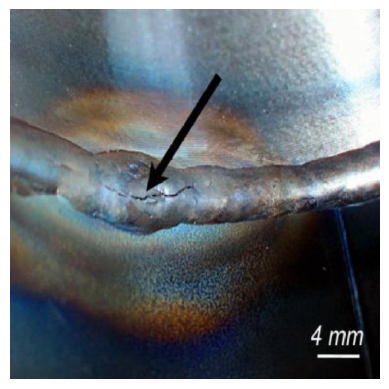

In [28]:
from PIL import Image
import numpy as np


img = Image.open(
"/content/runs/detect/predict-2/295992d6-f617b725-c1_png_jpg.rf.5f645e13f1695df588b0644ca9702c43.jpg"
)

cv2_img = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)

plt.imshow(cv2_img)
plt.axis("off")